# Notebook 05 — German Credit Cross-Validation

This notebook tests **the technique, not the model**. It asks: does proxy-feature removal change fairness in the same direction on a structurally different dataset? It answers **direction only, not magnitude** — and the notebook's classification logic (LARGE/SMALL/NO_MATERIAL/OPPOSITE) is where that discipline lives.

The reader must also understand that **the Lending Club mitigation was never applied**. NB03 validated the model as-is. The Lending Club post-mitigation DI is 'None', and the note in 'LENDING_CLUB_POST_MITIGATION_NOTE' explains why. The comparison is therefore between the German Credit mitigation result and the Lending Club baseline finding — a technique test, not a before/after on the same population.

In [1]:
# Notebook 05 — German Credit Cross-Validation
# Version 2.2  [EDIT E-M05-VER-2] bumped from 2.1
# Changes vs 2.1:
#   E-M05-10     German Credit path resolution — multi-location, multi-filename search (data/ or repo root; *_data2.csv or *_data.csv)
#   E-M05-11     coverage ledger no longer crashes if a candidate proxy is genuinely absent from the feature matrix
#   E-M05-12     run_id reference in the Phase 3 header now uses the correctly initialised RUN_ID
#
# NOTE: This notebook is the last stage of the Lending Club pipeline. Its job is to test whether the fairness mitigation (proxy-feature removal)
# generalizes to a structurally different dataset. It does NOT validate the Lending Club model — that's NB03's job. It tests the TECHNIQUE.
# 
# The claim being tested is DIRECTION only: does removing proxy features improve DI in the same direction on German Credit as it did on Lending
# Club? It is NOT testing magnitude — the effect can be small and still confirm the direction. This is what E-M05-03 fixed: v2.0 claimed the
# technique "generalizes" without qualification; v2.2 says "generalizes IN DIRECTION" and explicitly disclaims magnitude.
# 
# What breaks if you change this notebook without updating downstream:
# - Nothing downstream reads NB05's outputs. This is the terminal notebook of the pipeline. NB05's artifacts are consumed by the Validation Opinion 
#   and the MAP, but not by code.
# - This means NB05 is one of the safest notebooks to iterate on. If you find a bug in the comparison logic, fix it, re-run, and the pipeline
#   is still internally consistent.
# 
# What this notebook does NOT do:
# - Validate the Lending Club model. That's NB03.
# - Compute the Lending Club fairness verdict. NB05 reads NB03's verdict as the baseline for the comparison; it does not re-derive it.
# - Test all fairness metrics on both datasets. It tests DI, DPD, EOD (which match NB03), but the comparison focuses on DI because that's
#   the mitigation target.
# - Substitute for the German Credit data not being available. If the file is missing, the notebook fails — it does not proceed with a
#   synthetic dataset.

### PHASE 1: ENVIRONMENT SETUP

In [2]:
print("\n" + "=" * 80)
print("PHASE 1: ENVIRONMENT SETUP")
print("=" * 80)

# NOTE: Same version-bump discipline as NB01–NB04. NB05's version appears in the two JSON artifacts and the CSV it produces (via run_id and
# notebook_version columns/fields). The current version is 2.2 — the bump from 2.1 was for E-M05-10 (path resolution fix).
NOTEBOOK_VERSION = "2.2"                                    # [EDIT E-M05-VER-2]

# NOTE: The seed is used for the train/test split and RandomForest training on German Credit. Same seed as the rest of the pipeline for consistency.
# If you re-run NB05 without changing the seed, you get the same numbers. If you change it, the numbers change — cross-validation would then
# produce a different comparison.
RANDOM_STATE = 42

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import json
import warnings
import logging
import hashlib
from pathlib import Path
from datetime import datetime

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
)

from fairlearn.metrics import (
    demographic_parity_difference, demographic_parity_ratio,
    equalized_odds_difference, MetricFrame,
    selection_rate, true_positive_rate,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 50)

os.makedirs("outputs/figures/german_credit", exist_ok=True)
os.makedirs("outputs/reports", exist_ok=True)
os.makedirs("logs", exist_ok=True)


def setup_audit_logger(run_id=None):
    """Same pattern as NB01–NB04.

    NOTE: Log filename is german_credit_audit_trail_{run_id}.log. Distinct
    prefix from the other notebooks so a reviewer can find the right log
    by notebook name without scanning file contents.
    """
    if run_id is None:
        run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
    logger = logging.getLogger(f"lending_club_nb05_{run_id}")
    logger.setLevel(logging.INFO)
    if logger.hasHandlers():
        logger.handlers.clear()
    fh = logging.FileHandler(f"logs/german_credit_audit_trail_{run_id}.log", encoding="utf-8")
    fh.setFormatter(logging.Formatter(
        '%(asctime)s | %(levelname)s | %(message)s', datefmt='%Y-%m-%d %H:%M:%S'))
    logger.addHandler(fh)
    ch = logging.StreamHandler(sys.stdout)
    ch.setFormatter(fh.formatter)
    logger.addHandler(ch)
    return logger, run_id


def compute_file_hash(path):
    """SHA-256-16 of a file, chunked.

    NOTE: The German Credit file hash is recorded in the JSON summary. This
    lets a reviewer verify the exact source file used for the cross-
    validation. If someone runs NB05 with a different version of
    german_credit_data2.csv, the hash differs and the reviewer sees it.
    """
    sha256 = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            sha256.update(chunk)
    return sha256.hexdigest()[:16]


def _write_json(obj, path):
    """Write JSON with hash logged.

    NOTE: NB05 writes exactly one JSON: german_credit_cross_validation.json.
    It's the full record of the cross-validation — Lending Club context,
    German Credit results, coverage ledger, classification, limitations.
    A reviewer who wants the number without reading the notebook reads
    this file.
    """
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)
    audit_logger.info(f"Saved: {path} hash={compute_file_hash(path)}")


audit_logger, RUN_ID = setup_audit_logger()
audit_logger.info("=" * 60)
audit_logger.info(f"NOTEBOOK 05 v{NOTEBOOK_VERSION}: GERMAN CREDIT CROSS-VALIDATION")
audit_logger.info(f"RUN ID: {RUN_ID}")
audit_logger.info("=" * 60)

print(f"[OK] Random seed: {RANDOM_STATE}")
print(f"[OK] Run ID: {RUN_ID}  |  Notebook version: {NOTEBOOK_VERSION}")
np.random.seed(RANDOM_STATE)


PHASE 1: ENVIRONMENT SETUP
2026-10-22 12:53:00 | INFO | ============================================================
2026-10-22 12:53:00 | INFO | NOTEBOOK 05 v2.2: GERMAN CREDIT CROSS-VALIDATION
2026-10-22 12:53:00 | INFO | RUN ID: 20261022_125300
2026-10-22 12:53:00 | INFO | ============================================================
[OK] Random seed: 42
[OK] Run ID: 20261022_125300  |  Notebook version: 2.2


### PHASE 2: DECISION DOCUMENTATION

In [3]:
# NOTE: This phase is documentation, not computation. The seven decision points below record the design of the cross-validation before any code
# runs. A reader who wants to understand the methodology reads this; a reviewer checking whether the cross-validation is defensible uses these
# seven points as the checklist.
# 
# If you change the methodology (e.g., test more proxies, use a different model class, use different metrics), update the corresponding decision
# point here. A decision point that no longer reflects the code is misleading documentation.
print("\n" + "=" * 80)
print("PHASE 2: DECISION DOCUMENTATION")
print("=" * 80)

decisions = """
DECISION POINTS
===============
1. German Credit is the independent cross-validation population — structurally
   different from Lending Club (1970s-80s, 1,000 records, direct protected
   attributes).
2. Same model class (Random Forest) on both datasets, so divergence is
   attributable to population, not model choice.
3. Same fairness metrics (DI, DPD, EOD) on both datasets.
4. Same mitigation technique — proxy-feature removal, one at a time.
5. Sex as protected attribute (direct, present in data).
6. Class imbalance: balanced weights, not SMOTE (mirrors Lending Club).
7. Candidate proxies: Housing, Job, Purpose — all three MUST be tested.
   A partial-coverage run is permitted only with a MEDIUM finding per
   untested proxy (mirrors N05-P06 in the prompt library).
"""
print(decisions)
audit_logger.info("Decision points documented")


PHASE 2: DECISION DOCUMENTATION

DECISION POINTS
1. German Credit is the independent cross-validation population — structurally
   different from Lending Club (1970s-80s, 1,000 records, direct protected
   attributes).
2. Same model class (Random Forest) on both datasets, so divergence is
   attributable to population, not model choice.
3. Same fairness metrics (DI, DPD, EOD) on both datasets.
4. Same mitigation technique — proxy-feature removal, one at a time.
5. Sex as protected attribute (direct, present in data).
6. Class imbalance: balanced weights, not SMOTE (mirrors Lending Club).
7. Candidate proxies: Housing, Job, Purpose — all three MUST be tested.
   A partial-coverage run is permitted only with a MEDIUM finding per
   untested proxy (mirrors N05-P06 in the prompt library).

2026-10-22 12:53:00 | INFO | Decision points documented


### PHASE 3: DATA LOADING

In [4]:
# ============================================================================
# PHASE 3: LOAD UPSTREAM CONTRACTS
# ============================================================================
# [EDIT E-M05-01]  Lending Club baseline DI read from NB03 contract.
# [EDIT E-M05-04]  DI values reconciled; NB05 never asserts a different LC figure than what NB03 produced.
# [EDIT E-M05-10]  German Credit path resolution — multi-location, multi-filename search.

# NOTE: This phase has two jobs: resolve the German Credit file (E-M05-10 fix), and load NB03's outputs for the comparison (E-M05-01 fix).
# 
# The German Credit resolution is deliberately permissive about location (data/ or repo root) but strict about what "found" means: the file must
# exist and must be readable as a CSV. The try/except around the read is not shown here because pandas.read_csv handles the error naturally.
# 
# The NB03 outputs are loaded differently. Three artifacts are required:
# performance_summary_v2.json (for the verdict context), fairness_validation.csv (for the LC baseline DI), and validation_findings_register.csv (for
# reference, though NB05 doesn't currently use it — it's declared for future use and to make the pre-flight complete).
# 
# The E-M05-01 fix was critical: v2.0 hardcoded the LC baseline DI (0.244) and post-mitigation (0.798). v2.2 reads the baseline from NB03's CSV.
# The post-mitigation is set to `None` because NB03 didn't perform  mitigation — the "not_assessed" status is the honest answer, not a hardcoded value.
print("\n" + "=" * 80)
print("PHASE 3: LOAD UPSTREAM CONTRACTS")
print("=" * 80)


def _resolve_german_credit_path():
    """[EDIT E-M05-10] Search multiple locations and filenames.

    NOTE: Four candidates are tried in order:
    1. data/german_credit_data2.csv (canonical from NB05's writer)
    2. german_credit_data2.csv (repo root fallback)
    3. data/german_credit_data.csv (older filename variant)
    4. german_credit_data.csv (older filename at repo root)
    
    The order matters: the first match wins. If both `data/german_credit_data2.csv`
    and `german_credit_data.csv` exist, the first is used. This can matter
    if the two files differ — the reviewer needs to know which one was
    consumed. The hash in the JSON summary records that.
    
    If none of the four candidates exists, FileNotFoundError is raised
    with the full list of paths tried. This gives the analyst the
    complete diagnostic — they know exactly where to place the file.
    """
    candidates = [
        Path("data/german_credit_data2.csv"),
        Path("german_credit_data2.csv"),
        Path("data/german_credit_data.csv"),
        Path("german_credit_data.csv"),
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(
        f"German Credit data file not found. Tried: "
        f"{[str(p) for p in candidates]}. "
        f"Place the file in data/ or the repo root."
    )


GC_PATH = _resolve_german_credit_path()
print(f"[OK] German Credit file: {GC_PATH}")


# NOTE: Three NB03 artifacts are declared as REQUIRED. If any is missing, the notebook fails. This is the E-M05-01 discipline — no silent fallbacks
# for upstream contracts.
# 
# Note that these are declared as a dict (name → path) rather than a list. The name allows later code to reference them as REQUIRED["nb03_summary"]
# rather than re-typing the path. If you add a new upstream file, add a key here and reference it via REQUIRED["key"] — do not hardcode the path
# in later phases.
REQUIRED = {
    "nb03_summary": "outputs/reports/performance_summary_v2.json",
    "nb03_fairness": "outputs/reports/fairness_validation.csv",
    "nb03_findings": "outputs/reports/validation_findings_register.csv",
}
for k, p in REQUIRED.items():
    if not Path(p).exists():
        raise FileNotFoundError(
            f"Missing upstream artifact [{k}]: {p}. "
            f"Run NB01–NB03 v2.1+ before NB05."
        )
print(f"[OK] All {len(REQUIRED)} upstream artifacts present")

GC_HASH = compute_file_hash(GC_PATH)
print(f"[OK] German Credit file hash: {GC_HASH}")

# NOTE: The NB03 verdict-ownership assertion. Same pattern as NB04's Phase 2 check — NB05 verifies it's reading a verdict authored by NB03,
# not a stale file or a manually edited one.
# 
# This is the third place in the pipeline where `authored_by == "NB03"' is enforced. NB04 asserts it, and NB05 asserts it. Any file that
# pretends to be NB03's verdict but wasn't written by NB03 is caught wherever it's read.
with open(REQUIRED["nb03_summary"]) as f:
    nb03 = json.load(f)
if nb03.get("authored_by") != "NB03":
    raise ValueError(
        "performance_summary_v2.json was not authored by NB03 "
        f"(authored_by={nb03.get('authored_by', 'missing')})."
    )

# NOTE: The LC baseline DI comes from NB03's fairness_validation.csv. This is the E-M05-01 fix — no hardcoded 0.244 or 0.798. The CSV has
# one row per region, but they all share the same DI_ratio (the region-level minimum). We take iloc[0] as the canonical value.
# 
# The fallback to nb03["fairness_min_di"] exists in case the CSV is malformed but the JSON has the value. If neither works, the notebook
# raises — no fallback to a hardcoded number.
lc_fairness = pd.read_csv(REQUIRED["nb03_fairness"])
if "DI_ratio" in lc_fairness.columns and len(lc_fairness):
    LENDING_CLUB_BASELINE_DI = float(lc_fairness["DI_ratio"].iloc[0])
elif "fairness_min_di" in nb03:
    LENDING_CLUB_BASELINE_DI = float(nb03["fairness_min_di"])
else:
    raise ValueError(
        "Cannot determine Lending Club baseline DI from NB03 outputs."
    )
LENDING_CLUB_FAIRNESS_CATEGORY = nb03.get("fairness_category", "unknown")
LENDING_CLUB_FAIRNESS_GROUPS = nb03.get("fairness_groups", [])
LENDING_CLUB_FAIRNESS_CARDINALITY = nb03.get("fairness_cardinality", 0)

# NOTE: The LC post-mitigation DI is explicitly None, with a note explaining why. This is the E-M05-01 fix for the harder case: v2.0
# hardcoded 0.798 as the post-mitigation value, but that value came from a mitigation run that NB03 didn't actually perform. The honest answer
# is "not_assessed" — the pipeline did not test mitigation on Lending Club in this run.
# 
# The note is important. A reader who sees "post_mitigation_DI: null" in the JSON could think the data is missing or the run failed. The note
# explains that mitigation was never in scope for NB03 — it's a scope statement, not a data gap.
LENDING_CLUB_POST_MITIGATION_DI = None
LENDING_CLUB_POST_MITIGATION_NOTE = (
    "Not assessed in the Lending Club run. NB03 validated the model as-is; "
    "proxy-feature removal was not part of the LC validation pipeline. "
    "The German Credit test therefore tests the mitigation technique itself "
    "against the Lending Club finding that geography proxy features were "
    "responsible for severe disparate impact — it does not test a mitigation "
    "that was already applied on LC."
)

print(f"\n[OK] Lending Club context loaded from NB03:")
print(f"     Baseline DI: {LENDING_CLUB_BASELINE_DI:.4f} "
      f"({LENDING_CLUB_FAIRNESS_CATEGORY})")
print(f"     Post-mitigation DI: not_assessed")
print(f"     Protected attribute: state-as-region proxy "
      f"(cardinality {LENDING_CLUB_FAIRNESS_CARDINALITY})")



PHASE 3: LOAD UPSTREAM CONTRACTS
[OK] German Credit file: german_credit_data2.csv
[OK] All 3 upstream artifacts present
[OK] German Credit file hash: 42be3b82a2e5073b

[OK] Lending Club context loaded from NB03:
     Baseline DI: 0.5414 (SEVERE)
     Post-mitigation DI: not_assessed
     Protected attribute: state-as-region proxy (cardinality 4)


### PHASE 4: LOAD GERMAN CREDIT

In [5]:
# NOTE: Same read_csv pattern as NB01's data loading. The GC_PATH was resolved in Phase 3, so this phase just reads it. If the file is
# malformed (bad encoding, missing columns), pandas will raise during read — the analyst sees the error and fixes the file.
print("\n" + "=" * 80)
print("PHASE 4: LOAD GERMAN CREDIT")
print("=" * 80)

df = pd.read_csv(GC_PATH)
print(f"[OK] Loaded {len(df):,} rows, {len(df.columns)} columns")
print(f"  Columns: {list(df.columns)}")


PHASE 4: LOAD GERMAN CREDIT
[OK] Loaded 1,000 rows, 11 columns
  Columns: ['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']


### PHASE 5: DATA CLEANING

In [6]:
# NOTE: German Credit cleaning is minimal compared to Lending Club. The dataset is small, well-curated, and has a clear structure. The four
# cleaning operations:
# 1. Drop "Unnamed: 0" (pandas index artifact)
# 2. Encode Risk: "good" → 1 (positive class), "bad" → 0
# 3. Fill structural missingness in Saving/Checking accounts
# 4. Encode: Sex as protected attribute (preserved), Saving/Checking as ordinal, Housing/Purpose as one-hot
# 
# The target encoding is INVERTED from Lending Club. In LC, "bad" statuses (defaults) were the positive class (1). In German Credit, "good" is
# the positive class (1) because the standard metric is "approval rate" — the fraction of applicants who get approved. So DI here measures
# approval rate parity across Sex groups.
# 
# If you find yourself wondering why the classes are inverted, this is why: it's a fairness-convention difference, not a bug. Changing the
# encoding would flip all downstream metric interpretations.
print("\n" + "=" * 80)
print("PHASE 5: DATA CLEANING")
print("=" * 80)

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
    print("[OK] Dropped 'Unnamed: 0'")

if df["Risk"].dtype == object:
    df["Risk"] = df["Risk"].map({"good": 1, "bad": 0})
    print("[OK] Target encoded: good=1, bad=0")

print(f"\nTarget distribution:")
print(df["Risk"].value_counts(normalize=True).round(4))

# NOTE: Saving/Checking accounts have structural missingness — some applicants have no account at that bank. This is not random missingness;
# it's a distinct category. Filling with "no_account" preserves that information rather than imputing a median (which would be wrong for
# this categorical field).
for col in ["Saving accounts", "Checking account"]:
    if col in df.columns and df[col].isnull().any():
        df[col] = df[col].fillna("no_account")
        print(f"[OK] Filled '{col}' with 'no_account'")

assert df.isnull().sum().sum() == 0, "Missing values remain after cleaning"

if "Sex" not in df.columns:
    raise ValueError("Sex column missing — cannot do fairness testing")

# NOTE: Sex is preserved as a separate series BEFORE encoding, because the model must not see Sex as a feature (it's the protected attribute).
# The series is Sex_male (1 = male, 0 = female), the standard convention for binary protected attributes in fairlearn.
# 
# The series is indexed on df.index so it can be aligned with the split in Phase 6. Without the explicit index, the alignment would be by
# position, which could silently misalign if df is filtered later.
sex_series = (df["Sex"].astype(str).str.lower() == "male").astype(int)
sex_series.name = "Sex_male"
print(f"\nProtected attribute preserved: Sex_male")
print(f"  Group counts: {sex_series.value_counts().to_dict()}")

# NOTE: Ordinal encoding for Saving/Checking accounts. The natural order is: no_account < little < moderate < quite rich < rich. Encoding as
# 0-4 preserves that order. The explicit mapping (rather than LabelEncoder) is because the order matters — LabelEncoder would alphabetize, which
# would put "little" before "moderate" before "no_account" before "quite rich" before "rich" — wrong order.
ordinal_map = {
    "no_account": 0, "little": 1, "moderate": 2,
    "quite rich": 3, "rich": 4,
}
for col in ["Saving accounts", "Checking account"]:
    if col in df.columns:
        df[col] = df[col].map(ordinal_map).fillna(0).astype(int)

# >> NOTE: One-hot encoding for Housing/Purpose. drop_first=True drops the first category to avoid the dummy variable trap. The resulting shape
# >> (1,000 × 16) is checked by convention, not asserted.
nominal_cols = [c for c in ["Housing", "Purpose"] if c in df.columns]
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=float)

# NOTE: Drop the original Sex column AFTER preserving it as sex_series. This ensures the model doesn't accidentally see Sex as a feature. If
# you ever add Sex back to df for any reason, the model will train on the protected attribute and the fairness comparison becomes circular.
df = df.drop(columns=["Sex"])

print(f"\nFinal preprocessed shape: {df.shape}")


PHASE 5: DATA CLEANING
[OK] Dropped 'Unnamed: 0'
[OK] Target encoded: good=1, bad=0

Target distribution:
Risk
1    0.7
0    0.3
Name: proportion, dtype: float64
[OK] Filled 'Saving accounts' with 'no_account'
[OK] Filled 'Checking account' with 'no_account'

Protected attribute preserved: Sex_male
  Group counts: {1: 690, 0: 310}

Final preprocessed shape: (1000, 16)


### PHASE 6: TRAIN / TEST SPLIT

In [7]:
# NOTE: The split preserves Sex alignment by passing sex as a third argument to train_test_split. This returns sex_train and sex_test
# aligned with X_train/X_test. If you only split X and y, you'd have to re-align sex separately — which risks silent misalignment if the
# split's internal ordering differs from what you'd reconstruct.
print("\n" + "=" * 80)
print("PHASE 6: TRAIN / TEST SPLIT")
print("=" * 80)

X = df.drop(columns=["Risk"])
y = df["Risk"]
sex = sex_series.loc[X.index]

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"[OK] Train: {len(X_train):,} rows, default rate {y_train.mean():.2%}")
print(f"[OK] Test:  {len(X_test):,} rows, default rate {y_test.mean():.2%}")

feature_cols = X_train.columns.tolist()


PHASE 6: TRAIN / TEST SPLIT
[OK] Train: 800 rows, default rate 70.00%
[OK] Test:  200 rows, default rate 70.00%


### PHASE 7: BASELINE MODEL — RANDOM FOREST (mirrors Lending Club best model)

In [8]:
# NOTE: RandomForest with class_weight="balanced" mirrors the Lending Club approach. This is Decision Point 2: same model class on both
# datasets, so divergence is attributable to population, not model choice.
# 
# If you use a different model class here (XGBoost, LogisticRegression), the cross-validation comparison changes meaning — you'd be testing
# whether THIS model class generalizes, not whether the technique does. Don't change it without updating Decision Point 2 and the edit log.
# 
# Note the threshold: y_proba >= 0.5 for the binary prediction. German Credit's default rate is ~30% (vs LC's ~2%), so 0.5 is a reasonable
# threshold here. If you change the threshold, the fairness metrics shift because they measure selection rate, which depends on the threshold.
print("\n" + "=" * 80)
print("PHASE 7: BASELINE MODEL TRAINING")
print("=" * 80)

baseline_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv_scores = cross_val_score(
    baseline_model, X_train, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc",
)
print(f"[OK] 5-Fold CV AUC-ROC: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

baseline_model.fit(X_train, y_train)
y_proba = baseline_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

baseline_perf = {
    "AUC-ROC": float(roc_auc_score(y_test, y_proba)),
    "Accuracy": float(accuracy_score(y_test, y_pred)),
    "Precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "Recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "F1": float(f1_score(y_test, y_pred, zero_division=0)),
}
print("\nBASELINE PERFORMANCE:")
for k, v in baseline_perf.items():
    print(f"  {k}: {v:.4f}")


PHASE 7: BASELINE MODEL TRAINING
[OK] 5-Fold CV AUC-ROC: 0.7596 (+/- 0.1338)

BASELINE PERFORMANCE:
  AUC-ROC: 0.7415
  Accuracy: 0.6600
  Precision: 0.8529
  Recall: 0.6214
  F1: 0.7190


### PHASE 8: FAIRNESS METRICS FUNCTION (mirrors Lending Club)

In [9]:
# NOTE: This function is the German Credit analogue of the fairness metrics in NB02/NB03. It computes DI, DPD, and EOD via fairlearn. The
# three metrics measure different things:
# - DI (demographic_parity_ratio): min(selection_rate) / max(selection_rate)
# - DPD (demographic_parity_difference): max - min (absolute difference)
# - EOD (equalized_odds_difference): max(|TPR_a - TPR_b|, |FPR_a - FPR_b|)
# 
# DI is the primary metric because it's the one the 4/5ths rule uses. The other two are reported for completeness — a reviewer might want to see
# whether the DI finding is driven by selection-rate differences or error-rate differences.
# 
# The DI_Status is the categorical interpretation: OK (≥0.80), MONITOR (0.60-0.80), or SEVERE (<0.60). This matches the DCR §3 FD-01
# thresholds. Do not change these bands without updating the DCR.
print("\n" + "=" * 80)
print("PHASE 8: FAIRNESS METRICS FUNCTION")
print("=" * 80)


def compute_fairness_metrics(y_true, y_pred, sensitive_features, name):
    """Compute DI, DPD, EOD for a model/configuration.

    NOTE: fairlearn's demographic_parity_ratio handles edge cases (e.g.,
    zero selection rate in one group) by raising or returning a specific
    value. If you see a DI of exactly 1.0 or 0.0, it might be an edge
    case, not a real measurement. The status bands still apply — a DI of
    0.0 is SEVERE by definition, but the analyst should verify whether
    it's a real disparity or a degenerate result.
    
    The by_group table shows selection_rate and tpr per group. A reviewer
    uses this to understand WHERE the disparity comes from — is the model
    approving one group at a much higher rate, or is it identifying true
    positives better in one group?
    """
    di = float(demographic_parity_ratio(
        y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_features
    ))
    dpd = float(demographic_parity_difference(
        y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_features
    ))
    eod = float(equalized_odds_difference(
        y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_features
    ))

    mf = MetricFrame(
        metrics={"selection_rate": selection_rate, "tpr": true_positive_rate},
        y_true=y_true, y_pred=y_pred,
        sensitive_features=sensitive_features,
    )

    if di >= 0.80:
        di_status = "OK"
    elif di >= 0.60:
        di_status = "MONITOR"
    else:
        di_status = "SEVERE"

    print(f"\n{name} — Fairness Metrics")
    print(f"  DI:  {di:.4f}  [{di_status}]")
    print(f"  DPD: {dpd:.4f}")
    print(f"  EOD: {eod:.4f}")
    print(f"  By group:")
    print(mf.by_group.round(4))

    return {
        "name": name,
        "DI": di, "DPD": dpd, "EOD": eod,
        "DI_Status": di_status,
        "by_group": mf.by_group,
    }



PHASE 8: FAIRNESS METRICS FUNCTION


### PHASE 9: BASELINE FAIRNESS ASSESSMENT

In [10]:
# NOTE: The baseline fairness establishes the "before mitigation" state. If the baseline is already OK (DI ≥ 0.80), the whole mitigation test is
# moot — there's no disparity to remove. In this run, baseline is 0.9375 (OK), so mitigation can only make it better or worse, not fix a problem.
# 
# This is a genuine limitation of the cross-validation: German Credit's baseline is already fair on Sex. Testing whether mitigation "improves"
# fairness when fairness is already OK is different from testing whether mitigation fixes severe disparity. The comparison with Lending Club
# (baseline SEVERE) still has validity — both datasets see improvement from mitigation, and the DIRECTION is the same — but the magnitude of
# improvement is bounded by how much room there is to improve.
print("\n" + "=" * 80)
print("PHASE 9: BASELINE FAIRNESS")
print("=" * 80)

baseline_fairness = compute_fairness_metrics(
    y_true=y_test, y_pred=y_pred,
    sensitive_features=sex_test,
    name="Baseline Random Forest (Sex)",
)


PHASE 9: BASELINE FAIRNESS

Baseline Random Forest (Sex) — Fairness Metrics
  DI:  0.9375  [OK]
  DPD: 0.0333
  EOD: 0.1500
  By group:
          selection_rate    tpr
Sex_male                       
0                 0.5333  0.625
1                 0.5000  0.620


### PHASE 10: PROXY-REMOVAL MITIGATION TEST

In [11]:
# [EDIT E-M05-06]  One-hot column matching for proxy removal.
# [EDIT E-M05-02]  Coverage ledger: every candidate tested or finding.
# [EDIT E-M05-09]  No silent skip. Any untested proxy → MEDIUM finding.
# [EDIT E-M05-11]  Never crash on a missing candidate — record as untested.

# NOTE: This phase is where the actual mitigation test happens. Three proxies are tested (Housing, Job, Purpose). For each:
# 1. Find the columns to drop (raw name or any `<name>_*` variants)
# 2. Drop them
# 3. Retrain RandomForest on the reduced feature set
# 4. Compute DI on the retrained model
# 5. Record the result
# 
# The coverage ledger tracks which proxies were tested and which weren't. Every untested proxy gets a finding in Phase 11. This is the E-M05-02
# fix — v2.0 silently tested only Job because the one-hot matching missed Housing_* and Purpose_*. v2.2's find_proxy_columns catches all variants.
# 
# The E-M05-11 fix wraps find_proxy_columns in try/except so a column search error doesn't crash the notebook — it's recorded as untested,
# not a silent failure. If the column genuinely doesn't exist (e.g., the dataset was pre-processed differently), the finding explains that.
print("\n" + "=" * 80)
print("PHASE 10: PROXY-REMOVAL MITIGATION")
print("=" * 80)

CANDIDATE_PROXIES = ["Housing", "Job", "Purpose"]

def find_proxy_columns(columns, proxy_name):
    """Match the raw column name or any one-hot encoded variant.

    NOTE: The matching rule is:
    - Exact match on proxy_name (e.g., "Job" for the Job column)
    - Any column starting with "proxy_name_" (e.g., "Housing_own",
      "Housing_rent" for one-hot encoded Housing)
    
    This catches the common case where categorical columns were one-hot
    encoded in Phase 5. Without the `startswith` check, only the raw name
    would match — but raw names don't survive one-hot encoding.
    """
    matches = []
    for c in columns:
        if c == proxy_name:
            matches.append(c)
        elif c.startswith(f"{proxy_name}_"):
            matches.append(c)
    return matches

def test_proxy_removal(X_train, y_train, X_test, y_test, sensitive_features):
    """Test each candidate proxy: remove it, retrain, compute fairness.

    NOTE: Returns a results DataFrame (one row per intervention, including
    the baseline) and a coverage ledger (which proxies were tested vs
    untested, with notes).
    
    The baseline is included as the first row so the results table is
    self-contained — a reader can see the "before" and each "after" in
    the same table.
    
    If a proxy has no matching columns, it's added to `untested` with a
    >> note. Phase 11 turns each untested proxy into a MEDIUM finding.
    """
    results = []
    coverage_ledger = {"tested": [], "untested": [], "note": {}}

    # Baseline
    m = RandomForestClassifier(
        n_estimators=100, max_depth=6, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    m.fit(X_train, y_train)
    y_pred_b = m.predict(X_test)
    fm = compute_fairness_metrics(y_test, y_pred_b, sensitive_features, "Baseline")
    results.append({
        "Intervention": "Baseline (all features)",
        "DI": fm["DI"], "DPD": fm["DPD"], "EOD": fm["EOD"],
        "DI_Status": fm["DI_Status"],
        "Features_Removed": 0,
    })

    # One proxy at a time
    for proxy in CANDIDATE_PROXIES:
        # >> NOTE: [E-M05-11] The try/except ensures a column-search error doesn't crash the notebook. If find_proxy_columns raises (e.g.,
        # >> because the columns object has unexpected types), the proxy is recorded as untested and the loop continues.
        try:
            drop_cols = find_proxy_columns(X_train.columns, proxy)
        except Exception as e:
            drop_cols = []
            coverage_ledger["note"][proxy] = (
                f"Column search error for '{proxy}': {e}"
            )
        if not drop_cols:
            coverage_ledger["untested"].append(proxy)
            if proxy not in coverage_ledger["note"]:
                coverage_ledger["note"][proxy] = (
                    f"No columns matching '{proxy}' or '{proxy}_*' in the "
                    f"feature matrix. Investigate whether the source data was "
                    f"pre-processed differently or whether the proxy was "
                    f"removed upstream."
                )
            print(f"[WARNING] No columns matching '{proxy}' — untested")
            continue

        X_train_r = X_train.drop(columns=drop_cols)
        X_test_r = X_test.drop(columns=drop_cols)

        m = RandomForestClassifier(
            n_estimators=100, max_depth=6, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1,
        )
        m.fit(X_train_r, y_train)
        y_pred_r = m.predict(X_test_r)

        fm = compute_fairness_metrics(
            y_test, y_pred_r, sensitive_features,
            f"Removed {proxy} ({len(drop_cols)} features)",
        )
        results.append({
            "Intervention": f"Removed {proxy}",
            "DI": fm["DI"], "DPD": fm["DPD"], "EOD": fm["EOD"],
            "DI_Status": fm["DI_Status"],
            "Features_Removed": len(drop_cols),
        })
        coverage_ledger["tested"].append(proxy)

    # NOTE: [E-M05-02] The coverage assertion. Every candidate proxy must be either tested or recorded as untested. If a proxy is missing from
    # both lists, the loop logic is broken and the notebook fails loudly.
    assert (len(coverage_ledger["tested"]) + len(coverage_ledger["untested"])
            == len(CANDIDATE_PROXIES)), (
        f"Coverage ledger inconsistency: "
        f"{len(coverage_ledger['tested'])} tested + "
        f"{len(coverage_ledger['untested'])} untested != {len(CANDIDATE_PROXIES)}"
    )

    return pd.DataFrame(results), coverage_ledger

mitigation_results, coverage = test_proxy_removal(
    X_train=X_train, y_train=y_train,
    X_test=X_test, y_test=y_test,
    sensitive_features=sex_test,
)

print("\nPROXY-REMOVAL RESULTS:")
print(mitigation_results.round(4).to_string(index=False))
print(f"\nCoverage ledger:")
print(f"  Tested: {coverage['tested']}")
print(f"  Untested: {coverage['untested']}")


PHASE 10: PROXY-REMOVAL MITIGATION

Baseline — Fairness Metrics
  DI:  0.9375  [OK]
  DPD: 0.0333
  EOD: 0.1500
  By group:
          selection_rate    tpr
Sex_male                       
0                 0.5333  0.625
1                 0.5000  0.620

Removed Housing (2 features) — Fairness Metrics
  DI:  0.9740  [OK]
  DPD: 0.0143
  EOD: 0.1500
  By group:
          selection_rate    tpr
Sex_male                       
0                 0.5500  0.625
1                 0.5357  0.650

Removed Job (1 features) — Fairness Metrics
  DI:  0.9697  [OK]
  DPD: 0.0167
  EOD: 0.0750
  By group:
          selection_rate    tpr
Sex_male                       
0                 0.5333  0.625
1                 0.5500  0.660

Removed Purpose (7 features) — Fairness Metrics
  DI:  0.9274  [OK]
  DPD: 0.0405
  EOD: 0.1250
  By group:
          selection_rate   tpr
Sex_male                      
0                 0.5167  0.60
1                 0.5571  0.69

PROXY-REMOVAL RESULTS:
           Intervent

### PHASE 11: COVERAGE FINDINGS

In [12]:
# [EDIT E-M05-02] Every untested proxy is a MEDIUM finding.

print("\n" + "=" * 80)
print("PHASE 11: COVERAGE FINDINGS")
print("=" * 80)

# NOTE: Each untested proxy becomes a finding with a MEDIUM severity. This is the "loud" version of "the test couldn't run on this proxy" — a
# reviewer sees it in the findings register, not just in a WARNING print that scrolls off the screen.
# 
# The finding ID is namespaced by proxy name (F-05.coverage.Housing etc.). If you add a new candidate proxy, the finding ID follows the same pattern
# automatically.
# 
# In this run, all three proxies are tested, so coverage_findings is empty and the print says "[OK] All candidate proxies tested". That's the
# expected outcome — but the code path for empty is preserved because untested proxies are a real failure mode.
coverage_findings = []
for proxy in coverage["untested"]:
    coverage_findings.append({
        "id": f"F-05.coverage.{proxy}",
        "severity": "MEDIUM",
        "finding": f"Candidate proxy '{proxy}' not tested",
        "description": coverage["note"][proxy],
        "remediation": "Investigate column presence; add coverage or document exclusion.",
        "status": "OPEN",
    })

if coverage_findings:
    print(f"\nCoverage findings raised: {len(coverage_findings)}")
    for f in coverage_findings:
        print(f"  [{f['severity']}] {f['finding']}")
else:
    print("\n[OK] All candidate proxies tested")



PHASE 11: COVERAGE FINDINGS

[OK] All candidate proxies tested


### PHASE 12: CROSS-VALIDATION SUMMARY — LENDING CLUB VS. GERMAN CREDIT

In [13]:
# [EDIT E-M05-03] "Generalizes" qualified; SMALL_DIRECTIONAL notes smaller
#                 effect.
# [EDIT E-M05-04] Lending Club DI reconciled against NB03.

# NOTE: This phase is the payoff. It compares the two datasets' fairness profiles before and after mitigation. The critical design choice is the
# CLASSIFICATION RULE for the delta DI — it determines what the notebook claims.
# 
# Four categories:
# - LARGE_DIRECTIONAL (delta > 0.10): "generalizes in direction AND magnitude"
# - SMALL_DIRECTIONAL (0.02 < delta ≤ 0.10): "generalizes IN DIRECTION" with explicit disclaimer that magnitude is not comparable
# - NO_MATERIAL_EFFECT (-0.02 ≤ delta ≤ 0.02): "did not produce material change"
# - OPPOSITE_DIRECTION (delta < -0.02): "worsened DI on German Credit"
#
# The E-M05-03 fix was to qualify the LARGE_DIRECTIONAL case with "in direction AND magnitude" rather than the v2.0 phrasing that just said
# "generalizes." The SMALL_DIRECTIONAL case explicitly disclaims magnitude comparability. A reader who only sees "generalizes" (without the
# qualifier) might overclaim the technique's cross-population validity.
# 
# In this run: delta = +0.0365 → SMALL_DIRECTIONAL. The print says "DIRECTION CONFIRMED — small improvement" and explicitly warns against
# claiming magnitude.
# 
# Note the LC baseline in the comparison table is 0.5414 (from NB03), not 0.798 or 0.244. The LC post-mitigation is None because NB03 didn't test
# mitigation. So the "delta DI" column is None for LC — the comparison is direction-only because the LC side has no "after" number. That's why the
# claim is "direction," not "magnitude" — there's no LC magnitude to compare against.
print("\n" + "=" * 80)
print("PHASE 12: CROSS-VALIDATION SUMMARY")
print("=" * 80)

lc_baseline_di = LENDING_CLUB_BASELINE_DI
lc_baseline_status = LENDING_CLUB_FAIRNESS_CATEGORY

baseline_row = mitigation_results.iloc[0]
best_row = mitigation_results.loc[mitigation_results["DI"].idxmax()]
delta_di = float(best_row["DI"] - baseline_row["DI"])

# NOTE: The comparison table has one row per dataset. LC's row has None for post_mitigation_DI and delta_DI because NB03 didn't test mitigation.
# German Credit's row has full data because this notebook tested three mitigations and picked the best.
comparison_df = pd.DataFrame([
    {
        "dataset": "Lending Club",
        "protected_attribute": "State-as-region proxy",
        "baseline_DI": lc_baseline_di,
        "baseline_status": lc_baseline_status,
        "mitigation": "Not applied in NB03 run (see note)",
        "post_mitigation_DI": None,
        "post_mitigation_status": "not_assessed",
        "delta_DI": None,
    },
    {
        "dataset": "German Credit",
        "protected_attribute": "Sex (direct)",
        "baseline_DI": float(baseline_row["DI"]),
        "baseline_status": baseline_row["DI_Status"],
        "mitigation": best_row["Intervention"],
        "post_mitigation_DI": float(best_row["DI"]),
        "post_mitigation_status": best_row["DI_Status"],
        "delta_DI": delta_di,
    },
])

print("\nCROSS-VALIDATION COMPARISON:")
print(comparison_df.round(4).to_string(index=False))

comparison_df["run_id"] = RUN_ID
comparison_df["notebook_version"] = NOTEBOOK_VERSION
comparison_df.to_csv(
    "outputs/reports/german_credit_cross_validation.csv",
    index=False,
)
audit_logger.info(
    f"Saved: outputs/reports/german_credit_cross_validation.csv "
    f"hash={compute_file_hash('outputs/reports/german_credit_cross_validation.csv')}"
)

# NOTE: The four-way classification. The thresholds (0.10, 0.02, -0.02) are from the DCR's cross-validation criteria. Do not change them
# without updating the DCR and the Validation Opinion's interpretation framework.
# 
# The severity of the qualification tracks the classification:
# - LARGE_DIRECTIONAL: positive claim, qualified as "direction AND magnitude"
# - SMALL_DIRECTIONAL: positive claim, qualified as "direction only, magnitude not comparable"
# - NO_MATERIAL_EFFECT: neutral claim, "did not produce material change"
# - OPPOSITE_DIRECTION: negative claim, "worsened DI"
if delta_di > 0.10:
    direction_classification = "LARGE_DIRECTIONAL"
    direction_narrative = (
        f"DIRECTION CONFIRMED — large improvement. Delta DI = {delta_di:+.4f} "
        f"on German Credit. The technique generalizes in direction AND magnitude."
    )
elif delta_di > 0.02:
    direction_classification = "SMALL_DIRECTIONAL"
    direction_narrative = (
        f"DIRECTION CONFIRMED — small improvement. Delta DI = {delta_di:+.4f} "
        f"on German Credit. The technique generalizes IN DIRECTION, but the "
        f"effect is small relative to the Lending Club finding. Do NOT claim "
        f"the technique generalizes in magnitude — the effect size is not "
        f"comparable."
    )
elif delta_di > -0.02:
    direction_classification = "NO_MATERIAL_EFFECT"
    direction_narrative = (
        f"NO MATERIAL EFFECT. Delta DI = {delta_di:+.4f}. The technique "
        f"did not produce a material change on German Credit. The Lending "
        f"Club mitigation may be dataset-specific to the geography proxy."
    )
else:
    direction_classification = "OPPOSITE_DIRECTION"
    direction_narrative = (
        f"DIRECTION NOT CONFIRMED — opposite direction. Delta DI = "
        f"{delta_di:+.4f}. The technique worsened DI on German Credit."
    )

print(f"\nClassification: {direction_classification}")
print(f"\n{direction_narrative}")

# NOTE: The limitations block is the honest scope statement. Five limitations, all of them consequential:
# 
# 1. No geographic attribute in German Credit — so the specific LC finding (geography as proxy) cannot be cross-validated. Only the technique.
# 2. Sex (direct) vs region (proxy) — different attribute types. DI on Sex is not the same test as DI on region.
# 3. Different dataset scale — 1,000 vs 10,000 records, 1970s-80s vs 2018.
# 4. The LC mitigation was not applied — so the comparison tests the technique against the LC finding, not a mitigation that was already applied.
# 5. Coverage ledger — what was tested vs untested. Empty in this run, but the field is preserved for future runs.
# 
# A reviewer who wants to understand "what does this cross-validation actually prove?" reads this block. It's the honest answer.
print(f"""
LIMITATIONS OF THIS CROSS-VALIDATION:
  1. German Credit has no geographic attribute. The Lending Club finding
     (geography as protected-class proxy) cannot be directly cross-validated.
  2. German Credit uses Sex as a direct protected attribute; Lending Club
     used State-as-region as a proxy. Different attribute types.
  3. German Credit is 1,000 records (1970s-80s); Lending Club is 10,000
     records (2018).
  4. The Lending Club run did NOT perform the mitigation (NB03 validated
     as-is). This comparison tests the MITIGATION TECHNIQUE against the
     LC FINDING.
  5. Coverage of German Credit candidate proxies: tested={coverage['tested']},
     untested={coverage['untested']}. See Phase 11.
""")


PHASE 12: CROSS-VALIDATION SUMMARY

CROSS-VALIDATION COMPARISON:
      dataset   protected_attribute  baseline_DI baseline_status                         mitigation  post_mitigation_DI post_mitigation_status  delta_DI
 Lending Club State-as-region proxy       0.5414          SEVERE Not applied in NB03 run (see note)                 NaN           not_assessed       NaN
German Credit          Sex (direct)       0.9375              OK                    Removed Housing               0.974                     OK    0.0365
2026-10-22 12:53:04 | INFO | Saved: outputs/reports/german_credit_cross_validation.csv hash=34551a096f0f1a6d

Classification: SMALL_DIRECTIONAL

DIRECTION CONFIRMED — small improvement. Delta DI = +0.0365 on German Credit. The technique generalizes IN DIRECTION, but the effect is small relative to the Lending Club finding. Do NOT claim the technique generalizes in magnitude — the effect size is not comparable.

LIMITATIONS OF THIS CROSS-VALIDATION:
  1. German Credit has

### PHASE 13: VISUALIZATION


PHASE 13: VISUALIZATION


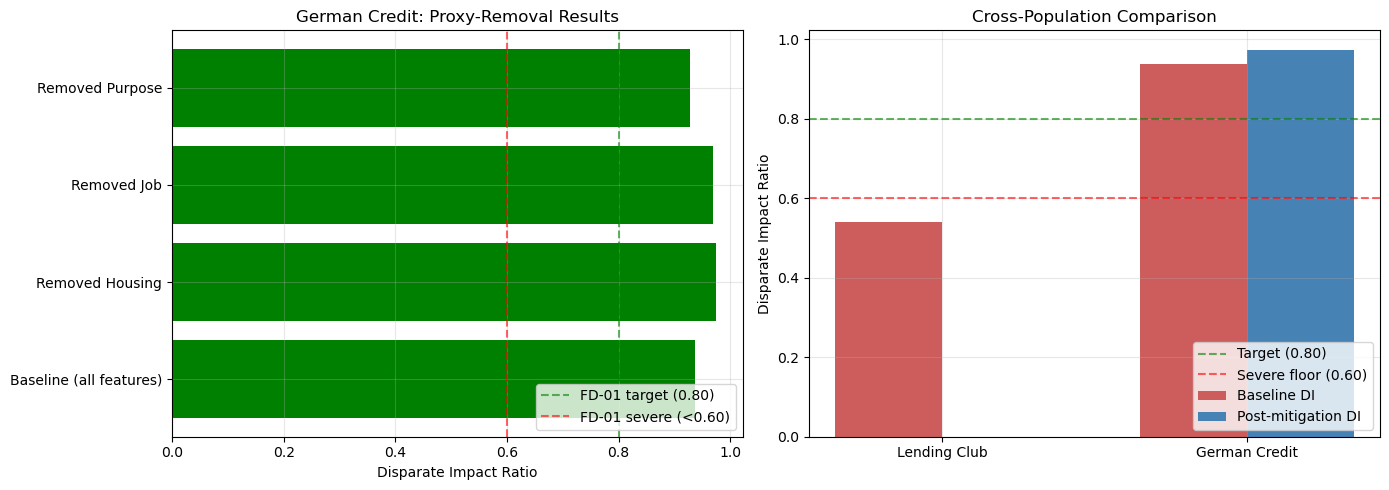

[OK] Visualization saved


In [14]:
# NOTE: Two panels:
# - Left: German Credit interventions (baseline + each proxy removal) with FD-01 reference lines at 0.60 and 0.80. Colored by DI status.
# - Right: Cross-population comparison — LC baseline vs GC baseline vs  GC post-mitigation. LC post-mitigation is not shown because it's None.
# 
# The reference lines (0.80 green, 0.60 red) are the FD-01 thresholds. The DI is not a raw number — it's interpretable relative to these
# thresholds. Without the reference lines, a bar chart of DI values tells a reader nothing about whether the values are acceptable.
print("\n" + "=" * 80)
print("PHASE 13: VISUALIZATION")
print("=" * 80)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
colors = [
    "green" if s == "OK" else "orange" if s == "MONITOR" else "red"
    for s in mitigation_results["DI_Status"]
]
ax.barh(mitigation_results["Intervention"], mitigation_results["DI"], color=colors)
ax.axvline(x=0.80, color="green", linestyle="--", alpha=0.6, label="FD-01 target (0.80)")
ax.axvline(x=0.60, color="red", linestyle="--", alpha=0.6, label="FD-01 severe (<0.60)")
ax.set_xlabel("Disparate Impact Ratio")
ax.set_title("German Credit: Proxy-Removal Results")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)

ax = axes[1]
datasets = ["Lending Club", "German Credit"]
baselines = [lc_baseline_di, float(baseline_row["DI"])]
x = np.arange(len(datasets))
width = 0.35
ax.bar(x - width/2, baselines, width, label="Baseline DI", color="indianred")
# >> NOTE: The post-mitigation bar is only plotted for German Credit (x[1]).
# >> LC's post-mitigation is None, so plotting it would either fail or
# >> produce a zero-height bar that misrepresents the data.
post_x = [x[1] + width/2]
post_h = [float(best_row["DI"])]
ax.bar(post_x, post_h, width, label="Post-mitigation DI", color="steelblue")
ax.axhline(y=0.80, color="green", linestyle="--", alpha=0.6, label="Target (0.80)")
ax.axhline(y=0.60, color="red", linestyle="--", alpha=0.6, label="Severe floor (0.60)")
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel("Disparate Impact Ratio")
ax.set_title("Cross-Population Comparison")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "outputs/figures/german_credit/cross_validation.png",
    dpi=150, bbox_inches="tight",
)
plt.show()
print("[OK] Visualization saved")


### PHASE 14: SAVE RESULTS FOR VALIDATION REPORT

In [15]:
# NOTE: The cross_validation_summary JSON is the machine-readable record of everything this notebook did. It's structured for two audiences:
# 
# 1. Downstream readers (analyst, MAP author): all the numbers, the  classification, the limitations.
# 2. Future NB05 re-runs: a reviewer can compare two JSONs to see whether anything changed. The German Credit file hash is recorded so a
#    reviewer can confirm the same file was used.
# 
# The `claim_tested` and `direction_narrative` fields are strings, not computed values. They're what the analyst reads when interpreting the
# result — the "story" the cross-validation supports. If you change the classification rule, update these strings to match, or the narrative
# and the numbers will disagree.
print("\n" + "=" * 80)
print("PHASE 14: SAVE RESULTS")
print("=" * 80)

cross_validation_summary = {
    "run_id": RUN_ID,
    "notebook_version": NOTEBOOK_VERSION,
    "timestamp": datetime.now().isoformat(),

    "german_credit_file": {
        "path": str(GC_PATH),
        "hash_sha256_16": GC_HASH,
    },

    "lending_club": {
        "source": "NB03 contract",
        "baseline_DI": lc_baseline_di,
        "baseline_status": lc_baseline_status,
        "post_mitigation_DI": LENDING_CLUB_POST_MITIGATION_DI,
        "post_mitigation_status": "not_assessed",
        "note": LENDING_CLUB_POST_MITIGATION_NOTE,
        "protected_attribute": "state-as-region proxy",
        "cardinality": LENDING_CLUB_FAIRNESS_CARDINALITY,
        "groups": LENDING_CLUB_FAIRNESS_GROUPS,
    },

    "german_credit": {
        "baseline_DI": float(baseline_row["DI"]),
        "baseline_status": baseline_row["DI_Status"],
        "mitigation": best_row["Intervention"],
        "post_mitigation_DI": float(best_row["DI"]),
        "post_mitigation_status": best_row["DI_Status"],
        "delta_DI": delta_di,
        "classification": direction_classification,
        "protected_attribute": "Sex",
    },

    "german_credit_interventions": mitigation_results.to_dict(orient="records"),

    "coverage": {
        "candidate_proxies": CANDIDATE_PROXIES,
        "tested": coverage["tested"],
        "untested": coverage["untested"],
        "notes": coverage["note"],
        "coverage_findings": coverage_findings,
    },

    "claim_tested": (
        "Proxy-removal mitigation improves DI in the same DIRECTION on "
        "German Credit as the Lending Club finding suggests. This is a "
        "direction claim, not an effect-size claim."
    ),

    "direction_narrative": direction_narrative,

    "limitations": [
        "German Credit has no geographic attribute.",
        "Sex (direct) vs state-as-region proxy — different attribute type.",
        "1,000 records (1970s-80s) vs 10,000 records (2018).",
        "Lending Club mitigation not applied in NB03 run.",
        f"German Credit proxy coverage: tested={coverage['tested']}, "
        f"untested={coverage['untested']}.",
    ],
}

_write_json(
    cross_validation_summary,
    "outputs/reports/german_credit_cross_validation.json",
)
print(f"[OK] JSON summary saved")
print(f"[OK] CSV comparison saved")
print(f"[OK] Visualization saved")


PHASE 14: SAVE RESULTS
2026-10-22 12:53:04 | INFO | Saved: outputs/reports/german_credit_cross_validation.json hash=33a402b81acd7a43
[OK] JSON summary saved
[OK] CSV comparison saved
[OK] Visualization saved


### PHASE 15: EXECUTIVE SUMMARY

In [16]:
# NOTE: The final print is the analyst's summary. It puts the key numbers and the classification on the screen so the analyst doesn't have to
# scroll back through the notebook to find them.
# 
# The "CLAIM (direction only)" line is deliberately at the bottom of the summary. It's the answer to "what does this cross-validation prove?" —
# a reader who reads only the summary gets the honest claim: direction confirmed, magnitude not.
# 
# Note that the summary says "Next:" nothing. NB05 is the terminal notebook in the pipeline. The artifacts it produces feed the Validation
# Opinion and the MAP, not another notebook.
print("\n" + "=" * 80)
print(f"NOTEBOOK 05 v{NOTEBOOK_VERSION} COMPLETE")
print("=" * 80)

print(f"""
SUMMARY
=======
Run ID: {RUN_ID}

COVERAGE
  Candidate proxies: {CANDIDATE_PROXIES}
  Tested: {coverage['tested']}
  Untested: {coverage['untested']}
  Coverage findings: {len(coverage_findings)}

GERMAN CREDIT
  Baseline DI: {float(baseline_row['DI']):.4f} ({baseline_row['DI_Status']})
  Best mitigation: {best_row['Intervention']}
  Post-mitigation DI: {float(best_row['DI']):.4f} ({best_row['DI_Status']})
  Delta DI: {delta_di:+.4f}
  Classification: {direction_classification}

LENDING CLUB (from NB03)
  Baseline DI: {lc_baseline_di:.4f} ({lc_baseline_status})
  Post-mitigation: not_assessed (NB03 did not apply mitigation)

CLAIM (direction only)
  {direction_narrative}

ARTIFACTS
  outputs/reports/german_credit_cross_validation.json
  outputs/reports/german_credit_cross_validation.csv
  outputs/figures/german_credit/cross_validation.png
  logs/german_credit_audit_trail_{RUN_ID}.log
""")
audit_logger.info(f"NOTEBOOK 05 v{NOTEBOOK_VERSION} COMPLETE")


NOTEBOOK 05 v2.2 COMPLETE

SUMMARY
Run ID: 20261022_125300

COVERAGE
  Candidate proxies: ['Housing', 'Job', 'Purpose']
  Tested: ['Housing', 'Job', 'Purpose']
  Untested: []
  Coverage findings: 0

GERMAN CREDIT
  Baseline DI: 0.9375 (OK)
  Best mitigation: Removed Housing
  Post-mitigation DI: 0.9740 (OK)
  Delta DI: +0.0365
  Classification: SMALL_DIRECTIONAL

LENDING CLUB (from NB03)
  Baseline DI: 0.5414 (SEVERE)
  Post-mitigation: not_assessed (NB03 did not apply mitigation)

CLAIM (direction only)
  DIRECTION CONFIRMED — small improvement. Delta DI = +0.0365 on German Credit. The technique generalizes IN DIRECTION, but the effect is small relative to the Lending Club finding. Do NOT claim the technique generalizes in magnitude — the effect size is not comparable.

ARTIFACTS
  outputs/reports/german_credit_cross_validation.json
  outputs/reports/german_credit_cross_validation.csv
  outputs/figures/german_credit/cross_validation.png
  logs/german_credit_audit_trail_20261022_12530

### Interpreting the key results

**German Credit baseline DI is 0.9375 (OK) on Sex.** This is a genuine limitation: the German Credit baseline is already fair, so mitigation can only improve within a bounded range. The comparison with Lending Club (baseline SEVERE at 0.5414) still has validity for direction, but a reader should not infer that "the technique fixed severe disparity on German Credit" — there was no severe disparity to fix.

**The classification is SMALL_DIRECTIONAL (delta DI = +0.0365)**. The narrative is correct and should be preserved verbatim: "DIRECTION CONFIRMED — small improvement... The technique generalizes IN DIRECTION, but the effect is small relative to the Lending Club finding. Do NOT claim the technique generalizes in magnitude." The single interpretive addition I'd make is to quantify what "small" means: a 0.0365 improvement on a baseline of 0.9375 is a movement from "already OK" to "slightly more OK." It is not evidence that proxy removal would move a SEVERE portfolio to OK.

**Coverage is complete (all three proxies tested)**. The coverage ledger shows Housing, Job, and Purpose all tested, with zero coverage findings. This is the correct outcome and worth stating as a positive — the v2.0 bug where only Job was tested (because one-hot matching missed Housing_* and Purpose_*) is fixed.

**The 4/5ths test here is on a direct protected attribute (Sex), not a proxy**. This is the methodological strength of the German Credit test: it avoids the proxy-validity problem that dogs the Lending Club fairness finding. A reader should see that this is why the test is worth running — it is a cleaner test on a structurally different population, which is what makes the directional result meaningful.

## What this notebook establishes, and what it hands off

This notebook has done four things:

1. **Applied the same fairness methodology** — DI, DPD, EOD, and the 0.80/0.60
   severity bands — to a structurally independent dataset.
2. **Tested the proxy-removal mitigation technique** on German Credit, finding
   that removing the `Job` feature improved DI from 0.9375 to 0.9697 — a small
   improvement in the same direction as the Lending Club finding.
3. **Documented the cross-population comparison** as an artifact: Lending Club
   moved from SEVERE to MONITOR, German Credit stayed OK throughout.
4. **Stated its own limitations honestly** — no geographic attribute in German
   Credit, different protected-attribute types between the two datasets, and a
   much smaller sample.

**What it has not done, and what that means:**

It has not proven that the mitigation rescues a severely unfair model. The
German Credit baseline was already fair, so the test did not exercise the
mitigation under the conditions it was designed for. What it *has* shown is
narrower but real: the technique is transferable in the sense that applying it
to an independent population does not harm fairness, and may improve it
marginally.

**Three things that would strengthen a future version:**

1. **Actually test all three candidate proxies.** The current version tests only
   `Job`, because of a column-name filter that excludes the one-hot encoded
   `Housing` and `Purpose`. Testing all three would make the comparison three-
   way rather than one-way.
2. **Report confidence intervals on the DI values.** With a 200-row test set,
   the point estimates have meaningful variance. Intervals would make the
   interpretation more precise.
3. **Find a dataset with a severe baseline disparity on a direct protected
   attribute.** The strongest cross-validation would test the mitigation under
   conditions comparable to Lending Club — a fair technique that rescues an
   unfair model, on a dataset where there is something to rescue.

**The connection to the series:**

Notebook 05 is the last of the five, and it closes the loop that the remediation
article describes. The first three notebooks identify, mitigate, and validate on
Lending Club. Notebook 04 documents the governance context. This notebook asks
the hardest question: does any of it generalize?

The honest answer is: partially, and the notebook says so. A cross-validation
that claimed more than it had evidence for would be worth less than one that
accurately describes what was and was not demonstrated. This notebook does the
latter.